In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve
)

# 1. Load Preprocessed Datasets
DATA_DIR = "../data/processed"

# Unscaled data (optimal for tree models)
X_train = pd.read_csv(f"{DATA_DIR}/X_train.csv")
X_test = pd.read_csv(f"{DATA_DIR}/X_test.csv")

# Scaled data (required for logistic regression)
X_train_scaled = pd.read_csv(f"{DATA_DIR}/X_train_scaled.csv")
X_test_scaled = pd.read_csv(f"{DATA_DIR}/X_test_scaled.csv")

# Target labels
y_train = pd.read_csv(f"{DATA_DIR}/y_train.csv").values.ravel()
y_test = pd.read_csv(f"{DATA_DIR}/y_test.csv").values.ravel()

print(f"Datasets successfully loaded:")
print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"Training Churn Count: {y_train.sum()} ({y_train.sum()/len(y_train)*100:.2f}%)")
print(f"Testing Churn Count : {y_test.sum()} ({y_test.sum()/len(y_test)*100:.2f}%)")

Datasets successfully loaded:
X_train: (8000, 15) | X_test: (2000, 15)
Training Churn Count: 1630 (20.38%)
Testing Churn Count : 407 (20.35%)


In [2]:
# 1. Baseline Logistic Regression (Standard)
lr_base = LogisticRegression(random_state=42, max_iter=1000)
lr_base.fit(X_train_scaled, y_train)

# 2. Class-Weighted Logistic Regression (Banking Retention Priority)
lr_weighted = LogisticRegression(random_state=42, class_weight='balanced', max_iter=1000)
lr_weighted.fit(X_train_scaled, y_train)

# Predictions
y_pred_base = lr_base.predict(X_test_scaled)
y_pred_weighted = lr_weighted.predict(X_test_scaled)

y_prob_base = lr_base.predict_proba(X_test_scaled)[:, 1]
y_prob_weighted = lr_weighted.predict_proba(X_test_scaled)[:, 1]

# Evaluation Summary
print("=" * 60)
print("     BASELINE LOGISTIC REGRESSION (UNWEIGHTED)     ")
print("=" * 60)
print(classification_report(y_test, y_pred_base, target_names=['Stay (0)', 'Churn (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_base):.4f}")

print("\n" + "=" * 60)
print("    CLASS-WEIGHTED LOGISTIC REGRESSION (BALANCED)   ")
print("=" * 60)
print(classification_report(y_test, y_pred_weighted, target_names=['Stay (0)', 'Churn (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_weighted):.4f}")

     BASELINE LOGISTIC REGRESSION (UNWEIGHTED)     
              precision    recall  f1-score   support

    Stay (0)       0.85      0.96      0.91      1593
   Churn (1)       0.72      0.36      0.48       407

    accuracy                           0.84      2000
   macro avg       0.79      0.66      0.69      2000
weighted avg       0.83      0.84      0.82      2000

ROC-AUC Score: 0.8355

    CLASS-WEIGHTED LOGISTIC REGRESSION (BALANCED)   
              precision    recall  f1-score   support

    Stay (0)       0.92      0.76      0.84      1593
   Churn (1)       0.45      0.75      0.56       407

    accuracy                           0.76      2000
   macro avg       0.69      0.76      0.70      2000
weighted avg       0.83      0.76      0.78      2000

ROC-AUC Score: 0.8362


In [5]:
from xgboost import XGBClassifier

# Calculate positive class weight ratio for XGBoost (num_negative / num_positive)
scale_pos_weight = (len(y_train) - y_train.sum()) / y_train.sum()

# 1. Random Forest Classifier
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=8,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)
rf_model.fit(X_train, y_train)

# 2. XGBoost Classifier
xgb_model = XGBClassifier(
    n_estimators=150,
    max_depth=4,
    learning_rate=0.08,
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss'
)
xgb_model.fit(X_train, y_train)

# Generate Predictions & Probabilities on unscaled test data
y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

# Print Comparative Reports
print("=" * 60)
print("             RANDOM FOREST CLASSIFIER              ")
print("=" * 60)
print(classification_report(y_test, y_pred_rf, target_names=['Stay (0)', 'Churn (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")

print("\n" + "=" * 60)
print("                XGBOOST CLASSIFIER                 ")
print("=" * 60)
print(classification_report(y_test, y_pred_xgb, target_names=['Stay (0)', 'Churn (1)']))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_xgb):.4f}")

             RANDOM FOREST CLASSIFIER              
              precision    recall  f1-score   support

    Stay (0)       0.92      0.82      0.87      1593
   Churn (1)       0.51      0.73      0.60       407

    accuracy                           0.80      2000
   macro avg       0.72      0.78      0.74      2000
weighted avg       0.84      0.80      0.81      2000

ROC-AUC Score: 0.8641

                XGBOOST CLASSIFIER                 
              precision    recall  f1-score   support

    Stay (0)       0.93      0.82      0.87      1593
   Churn (1)       0.52      0.75      0.61       407

    accuracy                           0.81      2000
   macro avg       0.72      0.79      0.74      2000
weighted avg       0.84      0.81      0.82      2000

ROC-AUC Score: 0.8670


In [4]:
%pip install xgboost

  Using cached xgboost-3.4.1-py3-none-win_amd64.whl.metadata (2.0 kB)
Using cached xgboost-3.4.1-py3-none-win_amd64.whl (48.9 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: C:\Users\malli\Desktop\Banking-portfolio-performance-anlysis\venv\Scripts\python.exe -m pip install --upgrade pip


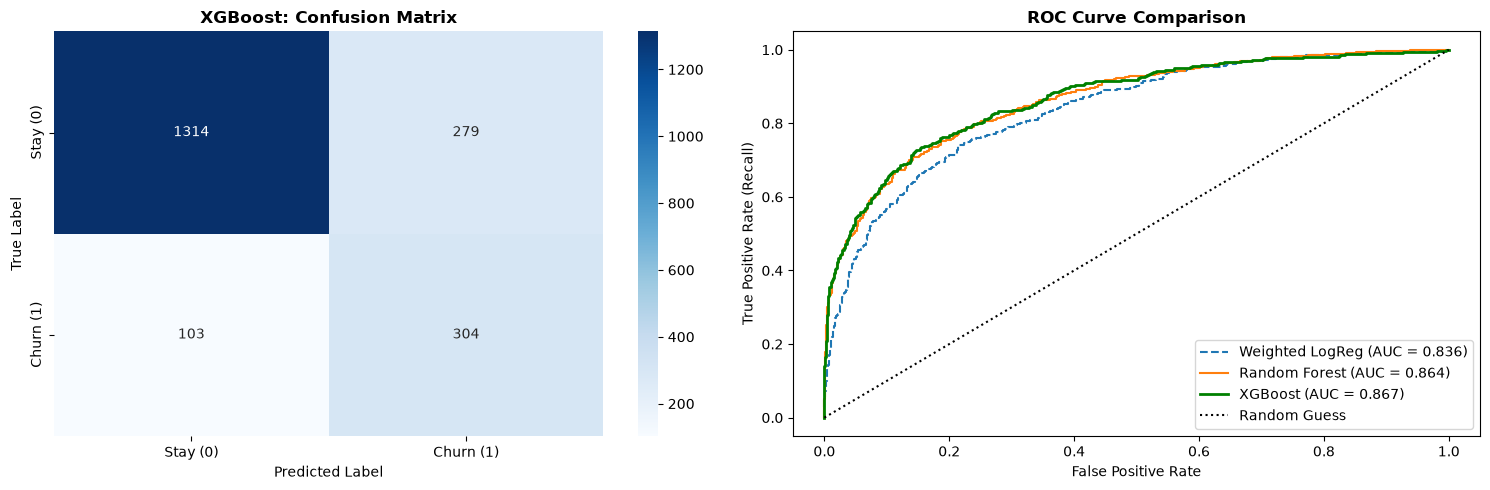

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1. Confusion Matrix for XGBoost
cm_xgb = confusion_matrix(y_test, y_pred_xgb)
sns.heatmap(
    cm_xgb, 
    annot=True, 
    fmt='d', 
    cmap='Blues', 
    xticklabels=['Stay (0)', 'Churn (1)'],
    yticklabels=['Stay (0)', 'Churn (1)'],
    ax=axes[0]
)
axes[0].set_title('XGBoost: Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. ROC Curves Comparison
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_prob_weighted)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_prob_xgb)

axes[1].plot(fpr_lr, tpr_lr, label=f'Weighted LogReg (AUC = {roc_auc_score(y_test, y_prob_weighted):.3f})', linestyle='--')
axes[1].plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_prob_rf):.3f})')
axes[1].plot(fpr_xgb, tpr_xgb, label=f'XGBoost (AUC = {roc_auc_score(y_test, y_prob_xgb):.3f})', color='green', linewidth=2)
axes[1].plot([0, 1], [0, 1], 'k:', label='Random Guess')

axes[1].set_title('ROC Curve Comparison', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate (Recall)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

C:\Users\malli\AppData\Local\Temp\ipykernel_17128\3036319867.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


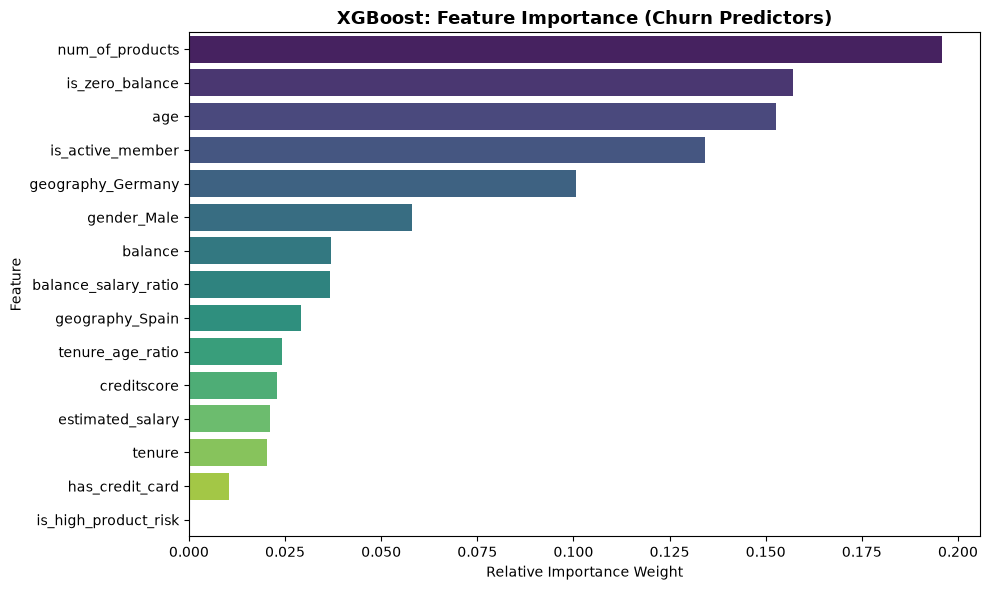

=== TOP 5 CHURN PREDICTORS ===
          Feature  Importance
  num_of_products    0.195932
  is_zero_balance    0.157015
              age    0.152623
 is_active_member    0.134132
geography_Germany    0.100581


In [7]:
# Extract feature importance from XGBoost
importance_df = pd.DataFrame({
    'Feature': X_train.columns,
    'Importance': xgb_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

# Visualize top predictive drivers
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df,
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title('XGBoost: Feature Importance (Churn Predictors)', fontsize=13, fontweight='bold')
plt.xlabel('Relative Importance Weight')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()

print("=== TOP 5 CHURN PREDICTORS ===")
print(importance_df.head(5).to_string(index=False))

In [9]:
import os
import joblib

# 1. Save trained XGBoost model to artifacts directory
MODEL_DIR = "../models"
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = f"{MODEL_DIR}/xgboost_churn_model.joblib"
joblib.dump(xgb_model, MODEL_PATH)
print(f"XGBoost model successfully saved to: {MODEL_PATH}")

# 2. Financial Portfolio Retention Calculation
# Link test predictions back to balance amounts to estimate balance exposure
test_results = X_test.copy()
test_results['actual_churn'] = y_test
test_results['predicted_churn'] = y_pred_xgb

# Portfolio values
total_churned_balance = test_results[test_results['actual_churn'] == 1]['balance'].sum()
identified_churn_balance = test_results[(test_results['actual_churn'] == 1) & (test_results['predicted_churn'] == 1)]['balance'].sum()
missed_churn_balance = test_results[(test_results['actual_churn'] == 1) & (test_results['predicted_churn'] == 0)]['balance'].sum()

print("\n" + "=" * 55)
print("       PORTFOLIO CAPITAL RISK & RETENTION IMPACT      ")
print("=" * 55)
print(f"Total Churned Capital at Risk: €{total_churned_balance:,.2f}")
print(f"Capital Flagged for Retention: €{identified_churn_balance:,.2f} ({identified_churn_balance/total_churned_balance*100:.2f}%)")
print(f"Unidentified / Missed Capital: €{missed_churn_balance:,.2f} ({missed_churn_balance/total_churned_balance*100:.2f}%)")

XGBoost model successfully saved to: ../models/xgboost_churn_model.joblib

       PORTFOLIO CAPITAL RISK & RETENTION IMPACT      
Total Churned Capital at Risk: €36,708,330.81
Capital Flagged for Retention: €27,829,242.11 (75.81%)
Unidentified / Missed Capital: €8,879,088.70 (24.19%)
